# 📡 Análise de Churn de uma Empresa de Internet por Assinatura

Estudo de caso de análise de dados e modelagem com **Python** e **SQL**, seguindo a metodologia **CRISP-DM**.

## Índice

1. Entendimento do Negócio e Contextualização
2. Bibliotecas Utilizadas
3. Carregamento dos Dados
4. Descrição dos Dados
5. Limpeza e Preparação dos Dados
6. Análise Exploratória
7. Modelagem
8. Conclusões e Recomendações
9. Deploy: Como Reproduzir este Projeto

# 1- Entendimento do Negócio e Contextualização

## A história da NetVida Telecom

Em 2019, em Curitiba (PR), o Sérgio e a Patrícia, dois amigos que trabalhavam com redes de computadores, ficaram incomodados com a internet lenta e cara do bairro onde moravam. Em vez de reclamar, resolveram instalar a própria rede de fibra óptica.

Começaram atendendo os vizinhos da rua. Deu tão certo que nasceu a **NetVida Telecom**, um provedor de internet por assinatura que hoje atende vários estados. Os planos variam de acordo com a velocidade, e os clientes podem contratar também serviços extras, como suporte técnico premium e TV por streaming.

Com o crescimento, apareceu um problema que não dá para resolver com mais cabos: **todo mês, parte dos clientes cancela o serviço**. Esse cancelamento tem nome, **churn**.

O Sérgio e a Patrícia sabem que conquistar um cliente novo custa muito mais do que manter um que já existe. Mas até hoje a retenção era feita no "feeling": ligavam para quem reclamava mais alto e deixavam passar quem cancelava em silêncio.

Agora eles querem decisões baseadas em dados. Por isso contrataram uma pessoa para analisar a base de clientes e descobrir **quem cancela, por quê e quem está prestes a cancelar**.

Esse alguém é você, o(a) analista de dados. 🚀

## Problema de negócio

> **Como reduzir o cancelamento de clientes da NetVida e usar os dados para agir antes que eles saiam?**

## Perguntas que a análise vai responder

1. Qual é a **taxa de churn** da empresa?
2. O churn muda conforme o **tipo de contrato** e o **plano**?
3. Clientes **novos** cancelam mais que os clientes antigos?
4. **Chamados de suporte** e **atrasos de pagamento** têm relação com o cancelamento?
5. Quais clientes ativos têm **maior risco** de cancelar?

## Objetivo do projeto

Entender o perfil de quem cancela e construir um modelo simples que aponte os clientes com maior risco, para a diretoria montar uma campanha de retenção.

## Sobre os dados

Os dados deste projeto são **fictícios**. Eles foram gerados por um script (`generate_data.py`) para simular a rotina de uma empresa real, incluindo problemas comuns como valores nulos e registros duplicados. Qualquer semelhança com empresas reais é coincidência.

## Ferramentas

- **Python** (pandas, matplotlib, seaborn e scikit-learn)
- **SQL** (SQLite)
- **Jupyter Notebook**
- **Git** para versionamento

# 2- Bibliotecas Utilizadas

Aqui ficam as bibliotecas que o projeto usa. Deixar tudo importado no começo do notebook ajuda quem for reproduzir a análise a ver rapidinho o que precisa ter instalado.

| Biblioteca | Para que serve neste projeto |
|---|---|
| `pandas` | Carregar, limpar e analisar as tabelas |
| `sqlite3` | Rodar consultas SQL dentro do notebook (já vem com o Python) |
| `matplotlib` | Criar os gráficos |
| `seaborn` | Deixar os gráficos mais bonitos e fáceis de montar |
| `scikit-learn` | Construir o modelo que aponta os clientes com risco de cancelar |

In [52]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 3- Carregamento dos Dados

A NetVida entregou os dados de 2025 em **três arquivos CSV**, que se relacionam entre si pelo código do cliente (`customer_id`):

| Arquivo | Conteúdo | Chave de ligação |
|---|---|---|
| `customers.csv` | Cadastro e contrato dos clientes | `customer_id` |
| `tickets.csv` | Chamados de suporte abertos | `ticket_id` e `customer_id` |
| `payments.csv` | Faturas mensais dos clientes | `invoice_id` e `customer_id` |

Vamos carregar cada arquivo em um DataFrame do pandas. As colunas de data já são lidas como data, para facilitar as análises por período.

In [2]:
customers = pd.read_csv('customers.csv', parse_dates=['signup_date', 'cancel_date'])
tickets = pd.read_csv('tickets.csv', parse_dates=['open_date'])
payments = pd.read_csv('payments.csv', parse_dates=['due_date','payment_date'])

print('customers:', customers.shape)
print('tickets:', tickets.shape)
print('payments:', payments.shape)

customers: (3020, 8)
tickets: (3597, 4)
payments: (30458, 5)


# 4- Descrição dos Dados

Antes de limpar ou analisar, precisamos **conhecer os dados**: como as tabelas são, quais colunas existem e de que tipo é cada uma.

## 4.1 Dicionário de dados

| Tabela | Coluna | Descrição |
|---|---|---|
| `customers` | `customer_id` | Código único do cliente |
| `customers` | `state` | Estado (UF) do cliente |
| `customers` | `signup_date` | Data de adesão ao serviço |
| `customers` | `plan` | Plano contratado (velocidade) |
| `customers` | `contract_type` | Tipo de contrato (Mensal, Anual ou Bienal) |
| `customers` | `payment_method` | Forma de pagamento |
| `customers` | `monthly_fee` | Mensalidade em reais |
| `customers` | `cancel_date` | Data de cancelamento (vazia se o cliente continua ativo) |
| `tickets` | `ticket_id` | Código único do chamado |
| `tickets` | `customer_id` | Cliente que abriu o chamado |
| `tickets` | `open_date` | Data de abertura do chamado |
| `tickets` | `reason` | Motivo do chamado |
| `payments` | `invoice_id` | Código único da fatura |
| `payments` | `customer_id` | Cliente dono da fatura |
| `payments` | `due_date` | Data de vencimento |
| `payments` | `payment_date` | Data do pagamento (vazia se a fatura não foi paga até o fim de 2025) |
| `payments` | `amount` | Valor da fatura em reais |

## 4.2 Primeiras linhas de cada tabela

In [3]:
display(customers.head())
display(tickets.head())
display(payments.head())

,customer_id,state,signup_date,plan,contract_type,payment_method,monthly_fee,cancel_date
0,1,SC,2021-10-08,Premium 600MB,Mensal,Pix,149.9,NaT
1,2,PR,2022-12-16,Intermediário 300MB,Bienal,Débito automático,109.9,NaT
2,3,PR,2022-07-05,Intermediário 300MB,Mensal,Boleto,109.9,NaT
3,4,NaN,2022-05-31,Básico 100MB,Mensal,Boleto,79.9,2025-10-23
4,5,RS,2023-11-25,Básico 100MB,Anual,Cartão de crédito,79.9,NaT


,ticket_id,customer_id,open_date,reason
0,1,2699,2025-01-01,Dúvidas
1,2,2143,2025-01-01,Dúvidas
2,3,1154,2025-01-01,Instalação
3,4,366,2025-01-01,Instalação
4,5,1854,2025-01-01,Queda de conexão


,invoice_id,customer_id,due_date,payment_date,amount
0,1,1,2025-01-10,2025-01-08,149.9
1,2,2,2025-01-10,2025-01-09,109.9
2,3,3,2025-01-10,2025-01-13,109.9
3,4,4,2025-01-10,2025-01-09,79.9
4,5,5,2025-01-10,2025-01-07,79.9


## 4.3 Tipos de dados de cada coluna

In [4]:
customers.info()
print('\n')
tickets.info()
print('\n')
payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 3020 entries, 0 to 3019
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customer_id     3020 non-null   int64         
 1   state           2929 non-null   str           
 2   signup_date     3020 non-null   datetime64[us]
 3   plan            3020 non-null   str           
 4   contract_type   3020 non-null   str           
 5   payment_method  3020 non-null   str           
 6   monthly_fee     2960 non-null   float64       
 7   cancel_date     717 non-null    datetime64[us]
dtypes: datetime64[us](2), float64(1), int64(1), str(4)
memory usage: 188.9 KB


<class 'pandas.DataFrame'>
RangeIndex: 3597 entries, 0 to 3596
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   ticket_id    3597 non-null   int64         
 1   customer_id  3597 non-null   int64         
 2   open_dat

## 4.4 Valores nulos

Primeiro, quantos valores vazios existem em cada coluna. Lembrando que nem todo vazio é problema: `cancel_date` vazia significa cliente ativo e `payment_date` vazia significa fatura não paga.

In [7]:
print(customers.isnull().sum())
print('\n')
print(tickets.isnull().sum())
print('\n')
print(payments.isnull().sum())

customer_id          0
state               91
signup_date          0
plan                 0
contract_type        0
payment_method       0
monthly_fee         60
cancel_date       2303
dtype: int64


ticket_id      0
customer_id    0
open_date      0
reason         0
dtype: int64


invoice_id        0
customer_id       0
due_date          0
payment_date    604
amount            0
dtype: int64


## 4.5 Linhas duplicadas

Agora, quantas linhas estão repetidas em cada tabela.

In [9]:
print('customers:', customers.duplicated().sum())
print('tickets:', tickets.duplicated().sum())
print('payments:', payments.duplicated().sum())

customers: 20
tickets: 30
payments: 50


## 4.6 Textos escritos de formas diferentes

Em colunas de categoria, cada valor deveria estar escrito de **um único jeito**. Vamos olhar os valores únicos de `payment_method` e `reason`.

In [11]:
print(customers['payment_method'].unique())
print('\n')
print(tickets['reason'].unique())

<StringArray>
[               'Pix',  'Débito automático',             'Boleto',
  'Cartão de crédito',  'CARTÃO DE CRÉDITO',            'Boleto ',
  'DÉBITO AUTOMÁTICO', 'Cartão de crédito ',             'BOLETO',
 'Débito automático ',                'PIX',               'Pix ']
Length: 12, dtype: str


<StringArray>
[         'Dúvidas',       'Instalação', 'Queda de conexão',
         'Lentidão',         'Cobrança',         'lentidão',
          'DÚVIDAS',         'COBRANÇA', 'queda de conexão',
       'INSTALAÇÃO', 'QUEDA DE CONEXÃO',         'LENTIDÃO',
         'cobrança',          'dúvidas']
Length: 14, dtype: str


## 4.7 Datas que não fazem sentido

Um cliente não pode cancelar antes de ter contratado o serviço. Vamos conferir se existe algum caso assim.

In [12]:
print('cancel before signup:', (customers['cancel_date'] < customers['signup_date']).sum())
print('first cancel date:', customers['cancel_date'].min())

cancel before signup: 10
first cancel date: 2019-06-11 00:00:00


## 4.8 Resumo dos problemas encontrados

| Tabela | Problema | O que fazer na limpeza |
|---|---|---|
| `customers` | Estados vazios | Preencher com `'Não informado'` |
| `customers` | Mensalidades vazias | Preencher com o valor do plano do cliente |
| `customers` | Formas de pagamento escritas de jeitos diferentes | Padronizar a escrita |
| `customers` | Cancelamento antes da adesão | Manter o cliente como churn e descartar a data errada |
| `customers` | Linhas duplicadas | Remover as repetições |
| `tickets` | Motivos escritos de jeitos diferentes | Padronizar a escrita |
| `tickets` | Linhas duplicadas | Remover as repetições |
| `payments` | Linhas duplicadas | Remover as repetições |
| `payments` | Data de pagamento vazia | Manter: significa fatura não paga |

Com esse mapa em mãos, a limpeza na próxima seção fica direta ao ponto: cada problema encontrado aqui tem uma solução prevista.

# 5- Limpeza e Preparação dos Dados

Nesta etapa, cada problema encontrado na seção 4 recebe uma correção. Depois de cada uma, conferimos o resultado para ter certeza de que deu certo.

## 5.1 Limpeza da tabela `customers`

Correções desta tabela:
- Remover as linhas duplicadas
- Preencher os estados vazios com `'Não informado'`
- Preencher as mensalidades vazias com o valor do plano do cliente, já que cada plano tem um preço único
- Padronizar a escrita da forma de pagamento
- Criar a coluna `churn`, com 1 para quem cancelou e 0 para quem continua ativo
- Descartar as datas de cancelamento anteriores à adesão. Sabemos que esses clientes cancelaram, mas a data correta é impossível de recuperar, então eles continuam como churn e a coluna `churn` é a referência para saber quem cancelou

In [15]:
customers = customers.drop_duplicates().reset_index(drop=True)

customers['state'] = customers['state'].fillna('Não informado')
customers['monthly_fee'] = customers['monthly_fee'].fillna(customers.groupby('plan')['monthly_fee'].transform('max'))
customers['payment_method'] = customers['payment_method'].str.strip().str.capitalize()

customers['churn'] = customers['cancel_date'].notna().astype(int)
wrong_date = customers['cancel_date'] < customers['signup_date']
customers.loc[wrong_date, 'cancel_date'] = pd.NaT

In [17]:
print(customers.shape)
print('\n')
print(customers.duplicated().sum())
print('\n')
print(customers[['state', 'monthly_fee']].isnull().sum())
print('\n')
print(customers['payment_method'].unique())
print('\n')
print(customers['churn'].value_counts())
print('\n')
print((customers['cancel_date'] < customers['signup_date']).sum())

(3000, 9)


0


state          0
monthly_fee    0
dtype: int64


<StringArray>
['Pix', 'Débito automático', 'Boleto', 'Cartão de crédito']
Length: 4, dtype: str


churn
0    2288
1     712
Name: count, dtype: int64


0


## 5.2 Limpeza da tabela `tickets`

Correções desta tabela:
- Remover as linhas duplicadas
- Padronizar a escrita dos motivos (`'LENTIDÃO'` e `'lentidão'` viram `'Lentidão'`)

In [18]:
tickets = tickets.drop_duplicates().reset_index(drop=True)
tickets['reason'] = tickets['reason'].str.strip().str.capitalize()

In [19]:
print(tickets.shape)
print(tickets.duplicated().sum())
print(tickets['reason'].value_counts())

(3567, 4)
0
reason
Lentidão            897
Queda de conexão    846
Dúvidas             756
Cobrança            728
Instalação          340
Name: count, dtype: int64


## 5.3 Limpeza da tabela `payments`

Correção desta tabela:
- Remover as linhas duplicadas

As datas de pagamento vazias **não são um problema**: significam fatura não paga até o fim de 2025. Elas ficam como estão e serão tratadas como atraso na análise.

In [20]:
payments = payments.drop_duplicates().reset_index(drop=True)

In [21]:
print(payments.shape)
print(payments.duplicated().sum())
print(payments['payment_date'].isnull().sum())

(30408, 5)
0
603


## 5.4 Criação do banco de dados SQLite

Com os dados limpos, vamos criar um banco **SQLite** com as três tabelas. Assim, as perguntas de negócio podem ser respondidas com **SQL** e com **Python**, como acontece no dia a dia de um analista.

O banco é criado **na memória**: ele existe enquanto o notebook está aberto e é montado de novo a cada execução. Por isso não gera nenhum arquivo extra e o projeto continua simples de reproduzir.

In [25]:
conn = sqlite3.connect(':memory:')

customers.to_sql('customers', conn, index=False)
tickets.to_sql('tickets', conn, index=False)
payments.to_sql('payments', conn, index=False)

30408

In [26]:
query = '''
SELECT name
FROM sqlite_master
WHERE type = 'table'
'''
display(pd.read_sql(query, conn))

query = '''
SELECT (SELECT COUNT(*) FROM customers) AS total_customers,
       (SELECT COUNT(*) FROM tickets) AS total_tickets,
       (SELECT COUNT(*) FROM payments) AS total_payments
'''
display(pd.read_sql(query, conn))

,name
0,customers
1,tickets
2,payments


,total_customers,total_tickets,total_payments
0,3000,3567,30408


# 6- Análise Exploratória

Nesta etapa, cada pergunta de negócio da seção 1 é respondida com **SQL** e visualizada com **Python**.

## Como o churn é medido

- **Churn:** cliente que cancelou o serviço entre 01/01/2025 e 31/12/2025. Na base, ele é identificado pela coluna `churn` (1 para quem cancelou e 0 para quem continua ativo).
- **Taxa de churn:** percentual de clientes que cancelaram, em relação ao total de clientes da base.

## 6.1 Qual é a taxa de churn da empresa?

In [27]:
query = '''
SELECT CASE WHEN churn = 1 THEN 'Cancelou' ELSE 'Ativo' END AS customer_status,
       COUNT(*) AS total_customers,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM customers), 1) AS percentage
FROM customers
GROUP BY churn
ORDER BY churn DESC
'''

churn_rate = pd.read_sql(query, conn)
display(churn_rate)

,customer_status,total_customers,percentage
0,Cancelou,712,23.7
1,Ativo,2288,76.3


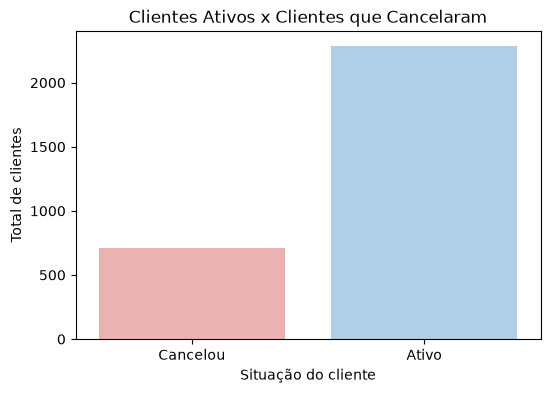

In [32]:
plt.figure(figsize=(6, 4))
sns.barplot(data=churn_rate, x='customer_status', y='total_customers', hue='customer_status',
            palette={'Ativo': '#a8d0f0', 'Cancelou': '#f4a9a8'}, legend=False)
plt.title('Clientes Ativos x Clientes que Cancelaram')
plt.xlabel('Situação do cliente')
plt.ylabel('Total de clientes')
plt.show()

### Observações

- Dos **3000 clientes** da base, **712 (23,7%)** cancelaram o serviço em 2025. Isso significa que cerca de 1 em cada 4 clientes saiu da NetVida no ano.
- A grande maioria (76,3%) continua ativa, mas uma perda desse tamanho em um único ano é relevante para uma empresa de assinatura.
- Este número é uma média geral. Ele não mostra **quais clientes** cancelam mais, e é isso que as próximas perguntas investigam.

### Recomendação

Tratar o churn como prioridade da diretoria e olhar os grupos de clientes que mais cancelam, para direcionar a campanha de retenção onde ela terá mais efeito.

## 6.2 O churn muda conforme o tipo de contrato e o plano?

Aqui vamos calcular a taxa de churn de cada grupo de clientes: de todos os clientes do grupo, qual percentual cancelou. Assim dá para comparar os grupos de forma justa, mesmo que eles tenham tamanhos diferentes.

### Churn por tipo de contrato

In [37]:
query = '''
SELECT contract_type,
       COUNT(*) AS total_customers,
       SUM(churn) AS canceled_customers,
       ROUND(SUM(churn) * 100.0 / COUNT(*), 1) AS churn_rate
FROM customers
GROUP BY contract_type
ORDER BY churn_rate DESC
'''

churn_by_contract = pd.read_sql(query, conn)
display(churn_by_contract)

,contract_type,total_customers,canceled_customers,churn_rate
0,Mensal,1494,513,34.3
1,Anual,910,135,14.8
2,Bienal,596,64,10.7


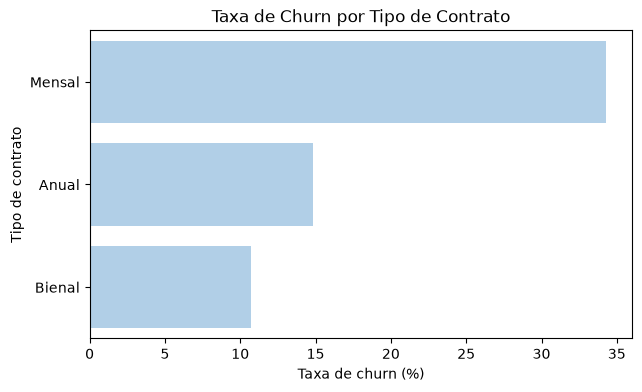

In [38]:
plt.figure(figsize=(7, 4))
sns.barplot(data=churn_by_contract, x='churn_rate', y='contract_type', color='#a8d0f0')
plt.title('Taxa de Churn por Tipo de Contrato')
plt.xlabel('Taxa de churn (%)')
plt.ylabel('Tipo de contrato')
plt.show()

### Churn por plano

In [39]:
query = '''
SELECT plan,
       COUNT(*) AS total_customers,
       SUM(churn) AS canceled_customers,
       ROUND(SUM(churn) * 100.0 / COUNT(*), 1) AS churn_rate
FROM customers
GROUP BY plan
ORDER BY churn_rate DESC
'''

churn_by_plan = pd.read_sql(query, conn)
display(churn_by_plan)

,plan,total_customers,canceled_customers,churn_rate
0,Básico 100MB,1336,350,26.2
1,Intermediário 300MB,1101,240,21.8
2,Premium 600MB,563,122,21.7


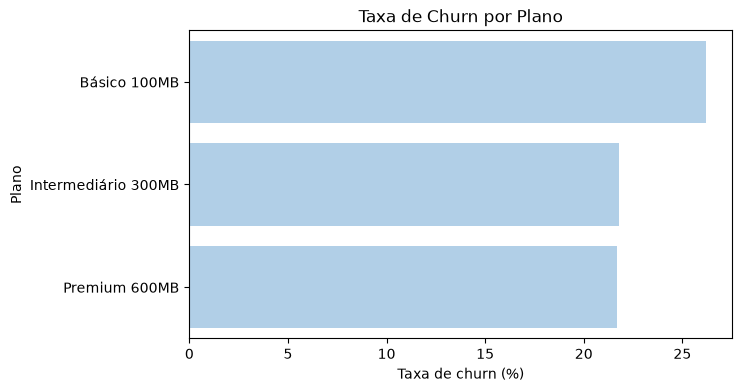

In [40]:
plt.figure(figsize=(7, 4))
sns.barplot(data=churn_by_plan, x='churn_rate', y='plan', color='#a8d0f0')
plt.title('Taxa de Churn por Plano')
plt.xlabel('Taxa de churn (%)')
plt.ylabel('Plano')
plt.show()

### Observações

- O **contrato Mensal** tem a maior taxa de churn, **34,3%**, bem acima da média geral de 23,7%. O contrato **Anual** tem 14,8% e o **Bienal** tem 10,7%.
- A taxa do contrato Mensal é mais que o dobro da do Anual e cerca de três vezes a do Bienal.
- O contrato Mensal concentra **513 dos 712 cancelamentos**, ou seja, cerca de 72% de todos os clientes que saíram.
- Quanto ao **plano**, o **Básico** tem a maior taxa, **26,2%**, enquanto o **Intermediário (21,8%)** e o **Premium (21,7%)** ficam praticamente iguais e abaixo da média geral.
- A diferença entre os planos é bem menor do que a diferença entre os contratos. Isso indica que o **tipo de contrato pesa mais** no cancelamento do que a velocidade contratada.
- Uma possível explicação para o contrato Mensal é a ausência de fidelidade, o que facilita a saída. Para o plano Básico, pode ser sensibilidade a preço. São hipóteses, porque a base não traz informações sobre multa contratual ou promoções.

### Recomendação

Priorizar a **migração de clientes do contrato Mensal para o Anual**, com um benefício como desconto na mensalidade ou instalação de um serviço extra. É o grupo que mais cancela e onde a ação de retenção tem mais efeito. O plano Básico merece atenção, mas como segunda prioridade.

## 6.3 Clientes novos cancelam mais que os antigos?

Aqui vamos calcular a taxa de churn de acordo com o ano em que o cliente aderiu ao serviço. Quanto mais recente o ano, menos tempo de casa o cliente tem.

In [41]:
query = '''
SELECT strftime('%Y', signup_date) AS signup_year,
       COUNT(*) AS total_customers,
       SUM(churn) AS canceled_customers,
       ROUND(SUM(churn) * 100.0 / COUNT(*), 1) AS churn_rate
FROM customers
GROUP BY signup_year
ORDER BY signup_year
'''

churn_by_year = pd.read_sql(query, conn)
display(churn_by_year)

,signup_year,total_customers,canceled_customers,churn_rate
0,2019,269,50,18.6
1,2020,433,90,20.8
2,2021,487,109,22.4
3,2022,488,94,19.3
4,2023,465,90,19.4
5,2024,506,174,34.4
6,2025,352,105,29.8


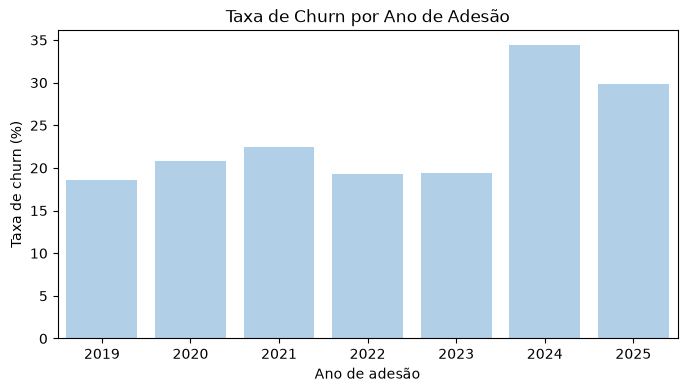

In [42]:
plt.figure(figsize=(8, 4))
sns.barplot(data=churn_by_year, x='signup_year', y='churn_rate', color='#a8d0f0')
plt.title('Taxa de Churn por Ano de Adesão')
plt.xlabel('Ano de adesão')
plt.ylabel('Taxa de churn (%)')
plt.show()

### Observações

- Os clientes que aderiram entre **2019 e 2023** têm taxa de churn parecida, entre **18,6% e 22,4%**, abaixo da média geral de 23,7%.
- Os clientes que aderiram em **2024 (34,4%)** e em **2025 (29,8%)** cancelam bem mais, com taxas acima da média geral.
- Ou seja, **clientes novos cancelam mais que os antigos**. A diferença aparece de forma clara a partir de quem tem menos de dois anos de casa.
- Uma possível explicação é que o cliente novo ainda está testando o serviço e é mais sensível a qualquer problema nos primeiros meses. É uma hipótese, porque a base não traz informações sobre a experiência de instalação ou o motivo do cancelamento.

### Recomendação

Criar uma **ação de acompanhamento no primeiro ano de contrato**, como contato após a instalação e pesquisa de satisfação nos primeiros meses, para resolver problemas antes que o cliente decida cancelar.

## 6.4 Chamados de suporte e atrasos de pagamento têm relação com o cancelamento?

### Churn por quantidade de chamados de suporte

Aqui vamos contar quantos chamados cada cliente abriu em 2025 e calcular a taxa de churn de cada grupo. Os clientes que nunca abriram chamado entram no grupo `0`. Quem abriu 4 chamados ou mais fica em um único grupo, porque são poucos clientes em cada quantidade acima de 4.

In [43]:
query = '''
WITH customer_tickets AS (
    SELECT c.customer_id,
           c.churn,
           COUNT(t.ticket_id) AS total_tickets
    FROM customers c
    LEFT JOIN tickets t ON c.customer_id = t.customer_id
    GROUP BY c.customer_id, c.churn
)
SELECT CASE WHEN total_tickets >= 4 THEN '4 ou mais' ELSE CAST(total_tickets AS TEXT) END AS tickets_group,
       COUNT(*) AS total_customers,
       SUM(churn) AS canceled_customers,
       ROUND(SUM(churn) * 100.0 / COUNT(*), 1) AS churn_rate
FROM customer_tickets
GROUP BY tickets_group
ORDER BY tickets_group
'''

churn_by_tickets = pd.read_sql(query, conn)
display(churn_by_tickets)

,tickets_group,total_customers,canceled_customers,churn_rate
0,0,978,113,11.6
1,1,1036,191,18.4
2,2,619,197,31.8
3,3,240,118,49.2
4,4 ou mais,127,93,73.2


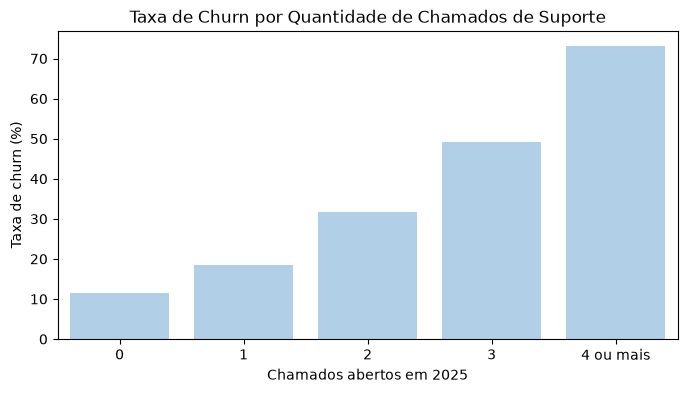

In [44]:
plt.figure(figsize=(8, 4))
sns.barplot(data=churn_by_tickets, x='tickets_group', y='churn_rate', color='#a8d0f0')
plt.title('Taxa de Churn por Quantidade de Chamados de Suporte')
plt.xlabel('Chamados abertos em 2025')
plt.ylabel('Taxa de churn (%)')
plt.show()

### Observações

- A taxa de churn **sobe a cada chamado a mais**: clientes sem nenhum chamado cancelam **11,6%**, e clientes com 4 chamados ou mais cancelam **73,2%**, mais de seis vezes a taxa do primeiro grupo.
- A partir de **2 chamados**, a taxa (31,8%) já passa da média geral de 23,7%. Com 3 chamados ela chega a 49,2%.
- Chamado de suporte é, portanto, um **forte sinal de alerta**: quanto mais um cliente precisa acionar o suporte, maior a chance de ele cancelar.
- Uma possível explicação é que o cliente que abre vários chamados está com um problema que não foi resolvido. É uma hipótese, porque esta análise só conta os chamados e não sabe se foram resolvidos nem como foi o atendimento.

### Recomendação

Criar um **alerta automático** para quando um cliente abrir o segundo chamado, acionando a equipe de retenção para resolver o problema e entrar em contato. O momento certo de agir é antes do terceiro chamado, quando a taxa de churn passa de 49%.

### Churn por quantidade de faturas atrasadas

Aqui vamos contar quantas faturas cada cliente pagou com atraso em 2025. Uma fatura é considerada **atrasada** quando foi paga depois do vencimento ou ainda não foi paga. Quem teve 4 faturas atrasadas ou mais fica em um único grupo.

Só entram clientes com pelo menos uma fatura. Ficam de fora **25 clientes** que cancelaram antes do primeiro vencimento, e por isso nunca tiveram uma fatura para atrasar.

In [45]:
query = '''
WITH customer_late AS (
    SELECT c.customer_id,
           c.churn,
           SUM(CASE WHEN p.payment_date IS NULL OR p.payment_date > p.due_date THEN 1 ELSE 0 END) AS late_invoices
    FROM customers c
    JOIN payments p ON c.customer_id = p.customer_id
    GROUP BY c.customer_id, c.churn
)
SELECT CASE WHEN late_invoices >= 4 THEN '4 ou mais' ELSE CAST(late_invoices AS TEXT) END AS late_group,
       COUNT(*) AS total_customers,
       SUM(churn) AS canceled_customers,
       ROUND(SUM(churn) * 100.0 / COUNT(*), 1) AS churn_rate
FROM customer_late
GROUP BY late_group
ORDER BY late_group
'''

churn_by_late = pd.read_sql(query, conn)
display(churn_by_late)

,late_group,total_customers,canceled_customers,churn_rate
0,0,946,176,18.6
1,1,1056,203,19.2
2,2,584,127,21.7
3,3,259,97,37.5
4,4 ou mais,130,84,64.6


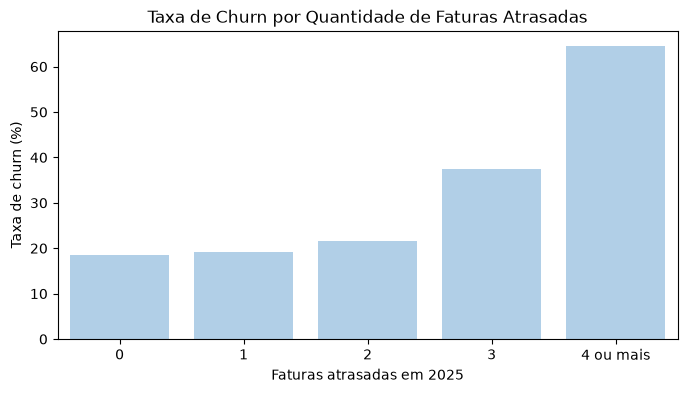

In [46]:
plt.figure(figsize=(8, 4))
sns.barplot(data=churn_by_late, x='late_group', y='churn_rate', color='#a8d0f0')
plt.title('Taxa de Churn por Quantidade de Faturas Atrasadas')
plt.xlabel('Faturas atrasadas em 2025')
plt.ylabel('Taxa de churn (%)')
plt.show()

### Observações

- Diferente dos chamados, aqui o crescimento **não é gradual**. Com 0, 1 ou 2 faturas atrasadas, a taxa de churn fica quase igual (**18,6%, 19,2% e 21,7%**), até abaixo da média geral de 23,7%.
- O salto acontece a partir da **terceira fatura atrasada**: a taxa vai para **37,5%** e chega a **64,6%** com 4 faturas ou mais.
- Atrasar uma ou duas faturas é comum e quase não indica risco. Mais da metade dos clientes (cerca de 55%) está nesse grupo.
- Uma possível explicação é que o atraso seja uma **consequência** do cancelamento, e não a causa: o cliente que já decidiu sair para de pagar em dia. É uma hipótese, porque a análise não mostra o que veio primeiro.

### Comparando com os chamados de suporte

| Sinal | Como a taxa de churn cresce | Quando o risco fica alto |
|---|---|---|
| Chamados de suporte | De forma gradual, a cada chamado | A partir do 2º chamado |
| Faturas atrasadas | Quase estável e depois com salto | A partir da 3ª fatura atrasada |

### Recomendação

Usar os dois sinais juntos: o **2º chamado** serve de alerta antecipado, e a **3ª fatura atrasada** serve de alerta de risco alto. Criar um alerta para qualquer fatura atrasada geraria muitos alarmes falsos.

## 7. Modelagem

Na análise exploratória a gente olhou cada fator separado. Agora vamos usar um **modelo de machine learning** para olhar todos juntos e responder duas perguntas:

1. **Quais fatores mais pesam** na decisão de cancelar?
2. **É possível prever** quais clientes têm mais chance de cancelar?

### Como vamos fazer

1. Montar uma **tabela única**, com uma linha por cliente e as informações que podem influenciar o cancelamento (contrato, plano, forma de pagamento, tempo de casa, chamados e faturas atrasadas).
2. Separar os dados em **treino** (o modelo aprende) e **teste** (a gente confere se ele acertou em clientes que ele nunca viu).
3. Treinar o modelo e **avaliar o resultado**.
4. Ver **quais fatores ele considerou mais importantes**.

### Cuidado importante

O modelo mostra **padrões**, não causas. E como os dados são de um único ano, ele serve para **priorizar quais clientes a equipe de retenção deve procurar primeiro**, e não para garantir quem vai cancelar.

### 7.1 Montando a tabela do modelo

O modelo precisa de uma tabela com **uma linha por cliente**. Vamos usar estas informações:

| Coluna | O que é |
|---|---|
| `contract_type` | Tipo de contrato |
| `plan` | Plano contratado |
| `payment_method` | Forma de pagamento |
| `tenure_months` | Meses de casa até 01/01/2025 (quem entrou em 2025 fica com 0) |
| `total_tickets` | Chamados de suporte abertos em 2025 |
| `late_invoices` | Faturas atrasadas em 2025 |
| `churn` | O que queremos prever: 1 cancelou, 0 continua ativo |

Clientes sem chamados ou sem faturas ficam com **0** nessas colunas.

In [47]:
query = '''
WITH ticket_count AS (
    SELECT customer_id,
           COUNT(*) AS total_tickets
    FROM tickets
    GROUP BY customer_id
),
late_count AS (
    SELECT customer_id,
           SUM(CASE WHEN payment_date IS NULL OR payment_date > due_date THEN 1 ELSE 0 END) AS late_invoices
    FROM payments
    GROUP BY customer_id
)
SELECT c.customer_id,
       c.contract_type,
       c.plan,
       c.payment_method,
       CAST(MAX(0, julianday('2025-01-01') - julianday(c.signup_date)) / 30 AS INTEGER) AS tenure_months,
       COALESCE(t.total_tickets, 0) AS total_tickets,
       COALESCE(l.late_invoices, 0) AS late_invoices,
       c.churn
FROM customers c
LEFT JOIN ticket_count t ON c.customer_id = t.customer_id
LEFT JOIN late_count l ON c.customer_id = l.customer_id
'''

model_data = pd.read_sql(query, conn)
display(model_data.head())
print(model_data.shape)

,customer_id,contract_type,plan,payment_method,tenure_months,total_tickets,late_invoices,churn
0,1,Mensal,Premium 600MB,Pix,39,2,0,0
1,2,Bienal,Intermediário 300MB,Débito automático,24,0,2,0
2,3,Mensal,Intermediário 300MB,Boleto,30,1,2,0
3,4,Mensal,Básico 100MB,Boleto,31,2,2,1
4,5,Anual,Básico 100MB,Cartão de crédito,13,0,0,0


(3000, 8)


In [48]:
model_data.isnull().sum()

customer_id       0
contract_type     0
plan              0
payment_method    0
tenure_months     0
total_tickets     0
late_invoices     0
churn             0
dtype: int64

### 7.2 Preparando os dados

O modelo só trabalha com números, então precisamos de dois ajustes:

1. **Transformar texto em colunas de 0 e 1.** Por exemplo, `contract_type` vira colunas como `contract_type_Mensal`, que vale 1 se o contrato é mensal e 0 se não é.
2. **Separar treino e teste.** Vamos usar **80% dos clientes para o modelo aprender** e **20% para testar**. Assim a gente confere se ele acerta em clientes que nunca viu.

Também separamos as colunas em dois grupos:

- **X**: as informações que o modelo usa para decidir.
- **y**: a resposta que queremos prever (`churn`).

In [50]:
X = model_data.drop(columns=['customer_id', 'churn'])
y = model_data['churn']

X = pd.get_dummies(X, columns=['contract_type', 'plan', 'payment_method'], drop_first=True)
X.head()

,tenure_months,total_tickets,late_invoices,contract_type_Bienal,contract_type_Mensal,plan_Intermediário 300MB,plan_Premium 600MB,payment_method_Cartão de crédito,payment_method_Débito automático,payment_method_Pix
0,39,2,0,False,True,False,True,False,False,True
1,24,0,2,True,False,True,False,False,True,False
2,30,1,2,False,True,True,False,False,False,False
3,31,2,2,False,True,False,False,False,False,False
4,13,0,0,False,False,False,False,True,False,False


In [51]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)

Treino: (2400, 10)
Teste: (600, 10)


### 7.3 Treinando o modelo

Vamos usar o **Random Forest** (floresta aleatória). Ele cria várias árvores de decisão, cada uma olhando os clientes de um jeito, e a resposta final sai da votação entre elas. Ele funciona bem com poucos ajustes e ainda mostra quais fatores pesaram mais.

O modelo aprende só com os dados de **treino**. Depois a gente avalia nos dados de **teste**.

In [53]:
model = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 T

In [54]:
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Ativo', 'Cancelou']))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

       Ativo       0.87      0.76      0.81       458
    Cancelou       0.45      0.63      0.53       142

    accuracy                           0.73       600
   macro avg       0.66      0.70      0.67       600
weighted avg       0.77      0.73      0.74       600

[[348 110]
 [ 52  90]]


### Resultado do modelo

No conjunto de teste, com **600 clientes** (142 cancelaram):

| | Previu ativo | Previu cancelou |
|---|---|---|
| **Era ativo** | 348 | 110 |
| **Cancelou** | 52 | 90 |

- **Recall de 63%:** o modelo identificou 90 dos 142 clientes que cancelaram.
- **Precision de 45%:** entre os 200 clientes que ele marcou como risco, 90 realmente cancelaram. É quase o dobro da taxa normal de cancelamento (23,7%).
- A **accuracy (73%)** não é uma boa medida aqui, porque ficou abaixo de simplesmente prever que ninguém cancela (76%). O modelo troca alguns acertos nos clientes ativos por mais acertos nos que cancelam, e isso é intencional.

### O que isso significa para o negócio

- O modelo **não acerta todos os casos**, mas funciona bem para **priorizar** quem a equipe de retenção deve procurar primeiro: o grupo marcado tem quase o dobro de chance de cancelar.
- Os **110 alarmes falsos** têm um custo (um contato ou uma oferta de desconto para quem ficaria de qualquer jeito). Os **52 cancelamentos não identificados** também têm custo (receita perdida). Cabe à empresa decidir qual erro pesa mais.

### Limitações

- Os dados cobrem apenas **um ano**, e os chamados e atrasos são contados até a data de cancelamento.
- O modelo aponta **padrões**, e não garante que um cliente vai cancelar.

### 7.4 Quais fatores mais pesam?

O Random Forest mostra a **importância** de cada coluna, ou seja, o quanto ela ajudou o modelo a separar quem cancela de quem fica. A soma de todas dá 100%.

In [55]:
importance = pd.DataFrame({'feature': X.columns, 'importance': model.feature_importances_})
importance['importance'] = (importance['importance'] * 100).round(1)
importance = importance.sort_values('importance', ascending=False).reset_index(drop=True)
display(importance)

,feature,importance
0,total_tickets,37.9
1,contract_type_Mensal,25.5
2,late_invoices,14.4
3,tenure_months,10.5
4,contract_type_Bienal,5.2
5,plan_Intermediário 300MB,2.0
6,payment_method_Débito automático,1.5
7,payment_method_Cartão de crédito,1.4
8,payment_method_Pix,0.9
9,plan_Premium 600MB,0.7


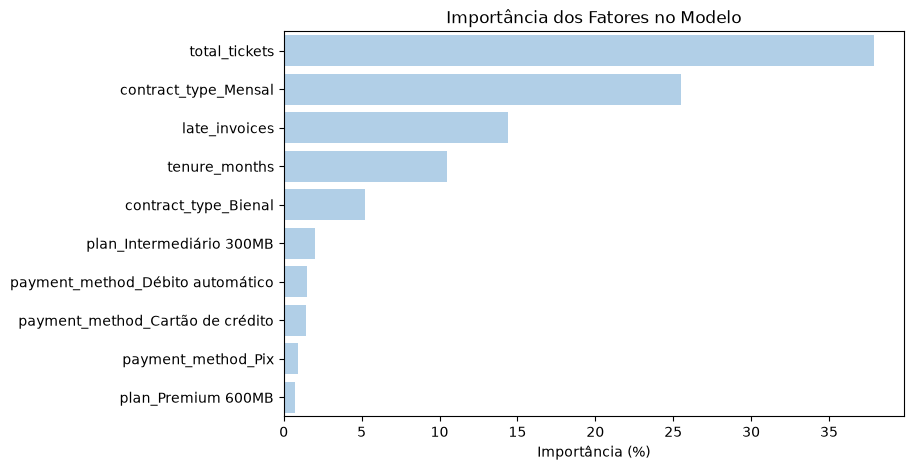

In [56]:
plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x='importance', y='feature', color='#a8d0f0')
plt.title('Importância dos Fatores no Modelo')
plt.xlabel('Importância (%)')
plt.ylabel('')
plt.show()

### Observações

Somando as colunas que foram divididas na preparação dos dados, o peso de cada fator na decisão do modelo ficou assim:

| Fator | Importância |
|---|---|
| Chamados de suporte | 37,9% |
| Tipo de contrato | 30,7% |
| Faturas atrasadas | 14,4% |
| Tempo de casa | 10,5% |
| Forma de pagamento | 3,8% |
| Plano | 2,7% |

- **Chamados de suporte** foi o fator mais importante, o que confirma o que a análise exploratória já mostrava: quanto mais chamados, maior a taxa de churn.
- O **tipo de contrato** vem em seguida. O contrato mensal é o que mais pesa, porque o cliente pode sair a qualquer momento, sem multa.
- **Faturas atrasadas** e **tempo de casa** têm peso médio. Juntos, os quatro primeiros fatores respondem por **mais de 93%** da decisão do modelo.
- **Forma de pagamento** e **plano** pesam pouco. Isso não significa que não tenham efeito, mas que, depois de considerar os outros fatores, ajudam pouco a separar quem cancela de quem fica.
- A importância mostra **quanto** cada fator pesa, mas não o **sentido**. A direção (por exemplo, mais chamados significa mais risco) vem da análise exploratória.

### Recomendações

1. **Monitorar os chamados de suporte** de cada cliente. É o sinal mais forte e o que aparece mais cedo.
2. **Incentivar a migração do contrato mensal para o anual**, com um desconto, por exemplo, já que o contrato é o segundo fator que mais pesa.
3. Dar atenção especial aos **clientes novos**, pois o tempo de casa também influencia.
4. Usar o modelo para gerar uma **lista de clientes em risco** todo mês, para a equipe de retenção priorizar.

## 8. Conclusões e Recomendações

### Resposta ao problema de negócio

A NetVida perdeu **712 de 3.000 clientes em 2025, uma taxa de churn de 23,7%**. A análise mostrou que o cancelamento **não acontece por acaso**: alguns sinais aparecem antes e permitem agir a tempo.

### Principais descobertas

1. **Chamados de suporte são o sinal mais forte.** A taxa de churn vai de 11,6% (nenhum chamado) para 73,2% (4 chamados ou mais), e é o fator que mais pesou no modelo (37,9%).
2. **O tipo de contrato faz muita diferença.** O contrato mensal tem 34,3% de churn, contra 14,8% do anual e 10,7% do bienal.
3. **Atrasos de pagamento só preocupam a partir da 3ª fatura.** Com 0 a 2 faturas atrasadas a taxa fica entre 18,6% e 21,7%. Com 3 sobe para 37,5%, e com 4 ou mais chega a 64,6%.
4. **Plano e forma de pagamento têm efeito menor.** O plano Básico (26,2%) e o boleto (28,3%) ficam acima da média, mas pesam pouco no modelo.
5. **O modelo de previsão ajuda a priorizar.** Ele encontrou 63% dos clientes que cancelaram, e entre os clientes que ele marcou como risco, 45% realmente cancelaram, quase o dobro da taxa normal.

### Recomendações

| Prioridade | Ação | Baseada em |
|---|---|---|
| 1 | Criar um **alerta no 2º chamado de suporte**, acionando a retenção para resolver o problema antes que o cliente cancele | Chamados |
| 2 | Oferecer **desconto para migrar do contrato mensal para o anual** | Tipo de contrato |
| 3 | Criar um alerta de **risco alto na 3ª fatura atrasada**, com contato e negociação | Faturas atrasadas |
| 4 | Gerar todo mês uma **lista dos clientes com maior risco**, usando o modelo, para a equipe de retenção priorizar | Modelo |

### Limitações

- Os dados cobrem **apenas um ano** e são **fictícios**, criados para este estudo de caso.
- O modelo mostra **padrões**, e não causas. Chamados e atrasos podem ser consequência da insatisfação, e não o motivo do cancelamento.
- Os chamados e as faturas atrasadas são contados até a data de cancelamento, então o modelo é útil para priorizar, mas não garante quem vai cancelar.

### Próximos passos

- Acompanhar o resultado das ações de retenção para saber se a taxa de churn realmente cai.
- Incluir novas informações no modelo, como o motivo e a resolução dos chamados.
- Testar outros modelos e comparar o desempenho.